![Banner](../images/09_13_banner_rs_soil_moisture.png)

# Water Cloud Model and Surface Scattering Inversion

Change detection ignores the canopy; physical retrievals model it. The Water Cloud Model (WCM)
treats a crop as a cloud of water droplets above the soil: the canopy scatters some of the radar
signal back and attenuates the rest on its way to and from the ground. Calibrated against field
measurements, it can be inverted for soil moisture under the crop. This notebook uses the SMAPVEX16
Iowa campaign, in which NASA and university teams measured surface soil moisture on 32 corn and
soybean fields in early June and August 2016, matched to Sentinel-1 backscatter, its incidence
angle and Sentinel-2 NDVI. It calibrates the WCM per crop, tests it with leave-one-field-out
cross-validation, compares vegetation descriptors, tries bare-soil scattering models (Oh, IEM) on
the early-season fields, and maps soil moisture over the campaign area.

## Overview

### The Water Cloud Model

For a vegetation descriptor `V` (NDVI, LAI or vegetation water content) and incidence angle `t`
(Attema and Ulaby 1978):

`sigma0 = A V^E cos(t) (1 - tau2) + tau2 sigma0_soil`, with `tau2 = exp(-2 B V / cos(t))`

The first term is the direct backscatter of the canopy, the second the soil backscatter attenuated
twice (two-way) by the canopy. The soil term is commonly linear in decibels, `sigma0_soil(dB) = C + D
theta`. `A`, `B`, `C` and `D` are calibrated per crop against field data; `E` is often fixed at 1.

### Surface scattering models

| Model | Type | Inputs | Validity |
|---|---|---|---|
| Oh (1992, 2004) | semi-empirical, from truck-mounted radar | theta (or permittivity), rms height `s`, angle | ks 0.1 to 6, theta 0.04 to 0.29 |
| Dubois et al. (1995) | semi-empirical | permittivity, `s`, angle | ks < 2.5, angle > 30 degrees, NDVI < 0.4 |
| IEM (Fung et al. 1992) | physical, integral equation | permittivity, `s`, correlation length `l`, correlation function | ks < 3 |

They need roughness, which is rarely known; inversion therefore searches soil moisture and
roughness together in a look-up table (LUT), and works only on bare or nearly bare fields.

### Vegetation descriptors

NDVI from optical images is easy to obtain but saturates in dense canopies and needs a clear day;
radar itself offers descriptors such as the cross-polarization ratio `VH/VV`, which grows with
volume scattering and is available on every pass.

## Physical Retrieval with GeoLattice

| Function | Purpose |
|---|---|
| `sm.water_cloud_model` | forward WCM in dB |
| `sm.calibrate_wcm` | least squares fit of A, B, C, D per group |
| `sm.invert_wcm` | analytical inversion to soil moisture, per group |
| `sm.oh_model`, `sm.dubois_model` | bare-soil backscatter |
| `sm.iem_lut`, `sm.invert_lut` | IEM look-up table and its inversion |
| `sd.smapvex16_samples`, `sd.smapvex16_scene` | campaign samples and a scene on a 20 m grid |

### Learning objectives

1. Match field soil moisture to SAR backscatter, incidence angle and an optical vegetation index.
2. Calibrate the Water Cloud Model per crop and judge it by leave-one-field-out cross-validation.
3. Compare NDVI and the radar cross-polarization ratio as vegetation descriptors.
4. Run Oh and IEM bare-soil models and invert a look-up table on early-season fields.
5. Map soil moisture under corn and soybean.

### Data

| Dataset | Content |
|---|---|
| SMAPVEX16 Iowa ThetaProbe (NSIDC `SV16I_TPSM`) | 0 to 5 cm soil moisture at 16 points per field, 32 fields, 12 days in May to June and August 2016 |
| Sentinel-1 RTC and GRD annotations | VV and VH gamma0 at 20 m on three relative orbits (63, 143, 165) and the incidence angle of each field |
| Sentinel-2 L2A | NDVI at each field, cloud-masked and interpolated to the radar dates |
| USDA CDL 2016 | corn and soybean fields for the map |

### Contents

- Setup
- The campaign samples
- Calibrating the Water Cloud Model
- Leave-one-field-out validation
- NDVI or the cross-polarization ratio
- Bare-soil models in early June
- A soil moisture map under the crops
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.soil_moisture as sm  # soil moisture physics, products, retrieval and validation
import sm_data as sd  # chapter helper: subsets, downloads and caches the data

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs")  # results written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
print("GeoLattice", geolattice.__version__, "| data folder", sd.DATA.relative_to(sd.DATA.parents[3]))  # versions and paths

df = sd.smapvex16_samples()  # matched samples: field, date, crop, ThetaProbe soil moisture, VV, VH, incidence, NDVI
df["incidence"] = df.incidence.fillna(df.groupby("orbit").incidence.transform("mean"))  # missing angles: mean of the orbit
df["xpr"] = 10 ** ((df.vh_db - df.vv_db) / 10)  # cross-polarization ratio VH/VV (linear)
df["iop"] = np.where(df.date.dt.month <= 6, "IOP1 (late May to early June)", "IOP2 (August)")  # campaign period
print(df.shape); display(df.groupby(["crop", "iop"]).agg(samples=("sm", "size"), fields=("site", "nunique"), sm=("sm", "mean"), ndvi=("ndvi", "mean"), vv=("vv_db", "mean")).round(3))  # overview

GeoLattice 0.3.49 | data folder GeoLattice/Data/08_remote_sensing/08_13_soil_moisture
(135, 15)


samples  fields     sm   ndvi     vv
crop iop                                                                
Corn IOP1 (late May to early June)       27      15  0.280  0.263 -8.285
     IOP2 (August)                       43      15  0.253  0.865 -8.659
Soy  IOP1 (late May to early June)       27      14  0.283  0.249 -8.180
     IOP2 (August)                       38      13  0.260  0.885 -7.725

## The campaign samples

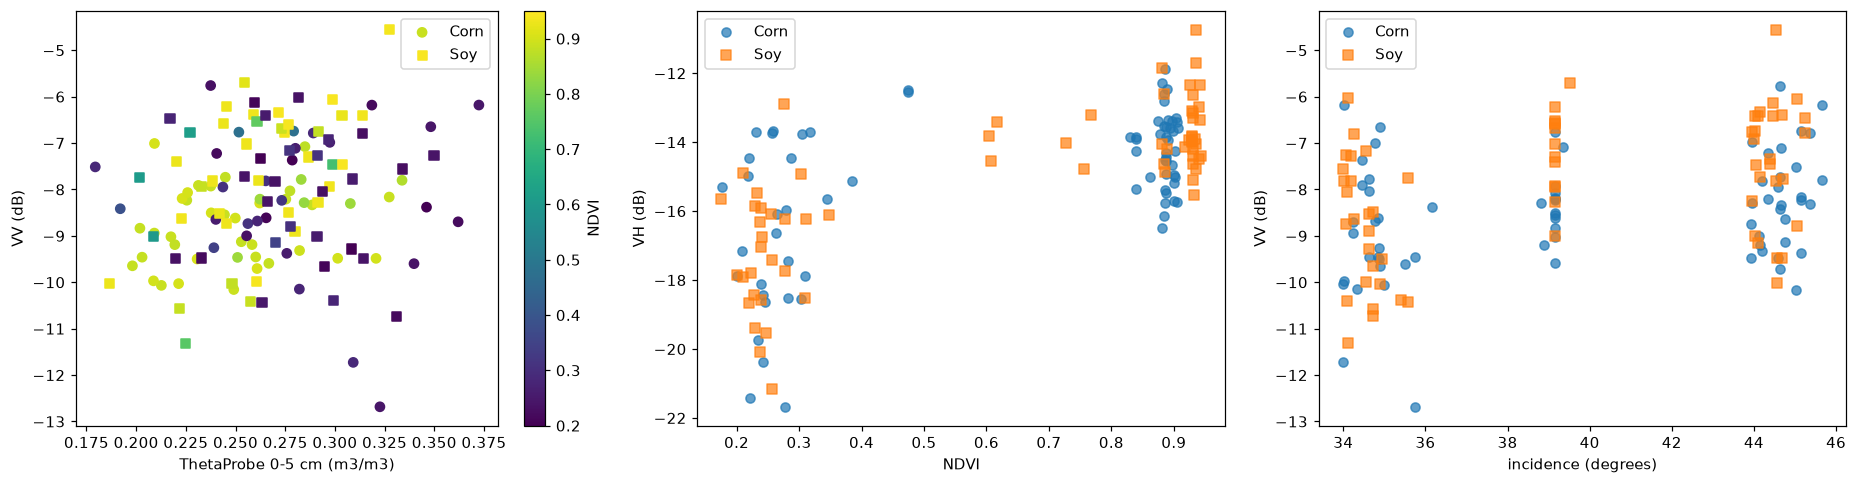

correlation of VV with soil moisture: {('Corn', 'IOP1 (late May to early June)'): -0.06, ('Corn', 'IOP2 (August)'): 0.25, ('Soy', 'IOP1 (late May to early June)'): -0.09, ('Soy', 'IOP2 (August)'): 0.51}


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))  # three views
for crop, m in (("Corn", "o"), ("Soy", "s")):  # each crop
    d = df[df.crop == crop]  # samples
    sc = ax[0].scatter(d.sm, d.vv_db, c=d.ndvi, cmap="viridis", vmin=0.2, vmax=0.95, marker=m, label=crop)  # VV vs soil moisture
    ax[1].scatter(d.ndvi, d.vh_db, marker=m, label=crop, alpha=0.7)  # VH vs NDVI
    ax[2].scatter(d.incidence, d.vv_db, marker=m, label=crop, alpha=0.7)  # VV vs angle
plt.colorbar(sc, ax=ax[0], label="NDVI")  # colour scale
ax[0].set_xlabel("ThetaProbe 0-5 cm (m3/m3)"); ax[0].set_ylabel("VV (dB)"); ax[0].legend()  # labels
ax[1].set_xlabel("NDVI"); ax[1].set_ylabel("VH (dB)"); ax[1].legend()  # labels
ax[2].set_xlabel("incidence (degrees)"); ax[2].set_ylabel("VV (dB)"); ax[2].legend()  # labels
plt.tight_layout(); plt.show()  # draw
print("correlation of VV with soil moisture:", df.groupby(["crop", "iop"]).apply(lambda d: d.sm.corr(d.vv_db)).round(2).to_dict())  # raw sensitivity

The raw relation is weak. On the early-June dates, when most fields were bare or had small plants,
VV hardly correlates with the field soil moisture (R about -0.1): differences in roughness and
tillage between fields dominate the backscatter. In August, under full canopies, the correlation is
0.25 over corn and 0.51 over soybean. The field soil moisture itself varies little, with a standard
deviation of only 0.039 m3 m-3 over all samples.

## Calibrating the Water Cloud Model

The model is fitted per crop on all samples, with NDVI as the vegetation descriptor and `E = 1`, once
without constraints and once with the soil sensitivity `D` bounded to 20 to 40 dB per m3 m-3, the range
reported for C-band over agricultural soils.

A      B       C       D  rmse_db  rmse_theta     n
              group                                                        
unconstrained Corn   0.00  0.066  -8.407   1.391    1.185       0.251  70.0
              Soy    1.00  0.017 -11.145  10.680    1.399       0.136  65.0
D bounded     Corn   0.17  0.223 -13.330  20.000    1.371       0.080  70.0
              Soy    1.00  0.022 -13.768  20.000    1.426       0.083  65.0

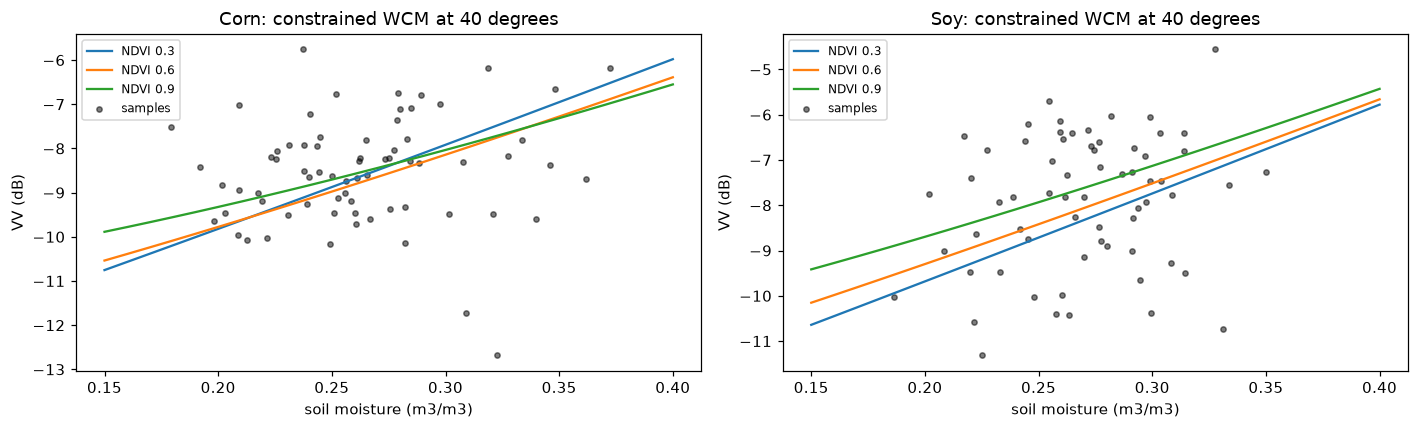

In [3]:
free = sm.calibrate_wcm(df.vv_db, df.sm, df.ndvi, df.incidence, groups=df.crop)  # unconstrained per-crop fit
BOUNDS = {"D": (20.0, 40.0)}  # physically plausible soil sensitivity (dB per m3/m3)
cal = sm.calibrate_wcm(df.vv_db, df.sm, df.ndvi, df.incidence, groups=df.crop, bounds=BOUNDS)  # constrained fit
display(pd.concat({"unconstrained": free, "D bounded": cal}).round(3))  # A, B, C, D, calibration RMSE (dB), retrieval RMSE, n
t = np.linspace(0.15, 0.40, 26)  # soil moisture axis
fig, ax = plt.subplots(1, 2, figsize=(13, 4))  # one panel per crop
for a, crop in zip(ax, ("Corn", "Soy")):  # each crop
    p = cal.loc[crop]  # parameters
    for v in (0.3, 0.6, 0.9):  # three canopies
        a.plot(t, sm.water_cloud_model(t, v, 40.0, A=p.A, B=p.B, C=p.C, D=p.D), label=f"NDVI {v}")  # model curve
    d = df[df.crop == crop]; a.scatter(d.sm, d.vv_db, s=12, c="k", alpha=0.5, label="samples")  # data
    a.set_title(f"{crop}: constrained WCM at 40 degrees"); a.set_xlabel("soil moisture (m3/m3)"); a.set_ylabel("VV (dB)"); a.legend(fontsize=8)  # labels
plt.tight_layout(); plt.show()  # draw

Without constraints the corn fit finds almost no soil sensitivity (`D` of about 1.4 dB per m3 m-3),
because the corn samples barely show one; inverting such a model amplifies every 0.1 dB of noise into
large soil moisture errors. Bounding `D` to the physical range moves both crops to the lower bound of
20 dB per m3 m-3 at a small cost in calibration RMSE (1.4 dB).

## Leave-one-field-out validation

The calibration RMSE flatters the model, because every field helped fit the parameters it is
tested on. Leaving out each field in turn, calibrating on the others and inverting the left-out
field gives an honest estimate of the retrieval error at a new field. The baseline to beat is
simply predicting the mean soil moisture of the campaign.

In [4]:
def loo(desc, bounds=None):  # leave-one-field-out retrieval with a given vegetation descriptor
    out = []  # predictions
    for site in df.site.unique():  # each field in turn
        train, test = df[df.site != site], df[df.site == site]  # split
        p = sm.calibrate_wcm(train.vv_db, train.sm, train[desc], train.incidence, groups=train.crop, bounds=bounds)  # fit on the others
        if test.crop.iloc[0] not in p.index:  # crop not calibrated
            continue
        pred = sm.invert_wcm(test.vv_db.values, test[desc].values, test.incidence.values, p.loc[test.crop.iloc[0]].to_dict())  # invert
        out.append(test.assign(pred=pred, mean_pred=train.sm.mean()))  # keep, with the campaign-mean baseline
    return pd.concat(out)  # all predictions


cv_free, cv = loo("ndvi"), loo("ndvi", BOUNDS)  # unconstrained and constrained
summary = pd.DataFrame({"WCM, unconstrained": sm.validation_metrics(cv_free.sm, cv_free.pred),
                        "WCM, D bounded": sm.validation_metrics(cv.sm, cv.pred),
                        "campaign mean (no satellite)": sm.validation_metrics(cv.sm, cv.mean_pred)}).T  # comparison
display(summary[["n", "bias", "rmse", "ubrmse", "pearson_r"]].astype(float).round(3))  # table
rows = []  # constrained model by crop and period
for key, g in cv.groupby(["crop", "iop"]):  # groups
    m = sm.validation_metrics(g.sm, g.pred)  # retrieval against ThetaProbe
    rows.append({"crop": key[0], "period": key[1], "n": int(m.n), "bias": m.bias, "ubrmse": m.ubrmse, "R": m.pearson_r})  # row
display(pd.DataFrame(rows).set_index(["crop", "period"]).round(3))  # table

,n,bias,rmse,ubrmse,pearson_r
"WCM, unconstrained",135.0,0.013,0.201,0.201,0.150
"WCM, D bounded",135.0,-0.003,0.085,0.085,0.216
campaign mean (no satellite),135.0,-0.000,0.039,0.039,-0.634


n   bias  ubrmse      R
crop period                                                 
Corn IOP1 (late May to early June)  27 -0.003   0.102 -0.117
     IOP2 (August)                  43 -0.002   0.068  0.347
Soy  IOP1 (late May to early June)  27 -0.005   0.081 -0.104
     IOP2 (August)                  38 -0.001   0.090  0.451

The honest test is sobering. The unconstrained model misses new fields by 0.20 m3 m-3 RMSE; the
constrained model by 0.085, with a correlation of 0.22; and simply predicting the campaign mean, with
no satellite at all, gives 0.039, because the soil moisture of these fields varied so little in this
summer. The model only shows skill in August (R 0.35 over corn and 0.45 over soybean), when the range
of conditions between fields was wider, and none in early June.

This is a common outcome of field campaigns, not a failure of the code. The ThetaProbe measures 0 to
5 cm and C-band senses 1 to 2 cm; soil sampling and the radar pass are up to a day apart; a 60 m window
at the field centre represents a field only roughly; and roughness, row direction and residue differ
between fields in ways the model does not know. Published WCM retrievals over crops reach 0.04 to 0.06
m3 m-3 mainly when parameters are calibrated per field over long time series, which removes the
field-to-field differences that dominate here.

## NDVI or the cross-polarization ratio

In [5]:
cv_x = loo("xpr", BOUNDS)  # radar cross-polarization ratio as descriptor
comp = pd.DataFrame({name: sm.validation_metrics(c.sm, c.pred)[["rmse", "ubrmse", "pearson_r"]] for name, c in
                     (("NDVI (Sentinel-2)", cv), ("VH/VV (Sentinel-1)", cv_x))}).T  # comparison
display(comp.astype(float).round(3))  # table

,rmse,ubrmse,pearson_r
NDVI (Sentinel-2),0.085,0.085,0.216
VH/VV (Sentinel-1),0.074,0.074,0.106


The radar cross-polarization ratio does slightly better than NDVI (RMSE 0.074 against 0.085) while
needing no clear optical image, although its correlation with the field soil moisture is lower.

## Bare-soil models in early June

On the first campaign dates most fields were bare or had small plants (NDVI below 0.4). There the
canopy can be neglected and a surface scattering model applies directly.

In [6]:
bare = df[(df.ndvi < 0.4)].copy()  # nearly bare fields
print(f"{len(bare)} samples with NDVI < 0.4")  # sample size
grid_t = np.round(np.arange(0.10, 0.46, 0.01), 2)  # LUT soil moisture
lut = sm.iem_lut(grid_t, [0.4, 0.7, 1.0, 1.5, 2.0], [4.0, 8.0, 12.0], [34.0, 35.0, 39.0, 44.0, 45.0], freq_ghz=5.405, pol="vv", clay=0.3)  # IEM look-up table
bare["iem_theta"] = sm.invert_lut(bare.vv_db.values, lut, incidence_deg=bare.incidence.values)  # LUT inversion
for s_ in (0.7, 1.0, 1.5):  # Oh 2004 for three roughness values
    bare[f"oh_vv_s{s_}"] = sm.oh_model(bare.sm.values, s_, bare.incidence.values)["vv"]  # forward VV
display(pd.DataFrame({"observed VV": [bare.vv_db.mean()], **{f"Oh 2004, s = {s_} cm": [bare[f'oh_vv_s{s_}'].mean()] for s_ in (0.7, 1.0, 1.5)}}).round(2))  # mean VV
m = sm.validation_metrics(bare.sm, bare.iem_theta)  # IEM retrieval
print(f"IEM LUT inversion of VV with unknown roughness: bias {m.bias:+.3f}, ubRMSE {m.ubrmse:.3f}, R {m.pearson_r:.2f}")  # metrics

54 samples with NDVI < 0.4


,observed VV,"Oh 2004, s = 0.7 cm","Oh 2004, s = 1.0 cm","Oh 2004, s = 1.5 cm"
0,-8.23,-11.12,-9.43,-7.68


IEM LUT inversion of VV with unknown roughness: bias +0.030, ubRMSE 0.102, R -0.16


Of the Oh 2004 curves, an rms height of 1.5 cm reproduces the mean early-June backscatter best
(-7.7 against -8.2 dB observed), a typical value for tilled fields. The IEM look-up table inversion
with roughness as a free parameter, however, does not retrieve the field differences (R -0.16,
ubRMSE 0.10 m3 m-3): with a single polarization, a rougher dry field and a smoother wet field have the
same VV, and the inversion cannot tell them apart. Multi-polarization or multi-angle data, or roughness
measured in the field, are needed for bare-soil inversion.

## A soil moisture map under the crops

The per-crop parameters are applied to the Sentinel-1 pass of 7 August 2016 (relative orbit 165)
with the nearest clear Sentinel-2 NDVI and the 2016 Cropland Data Layer.

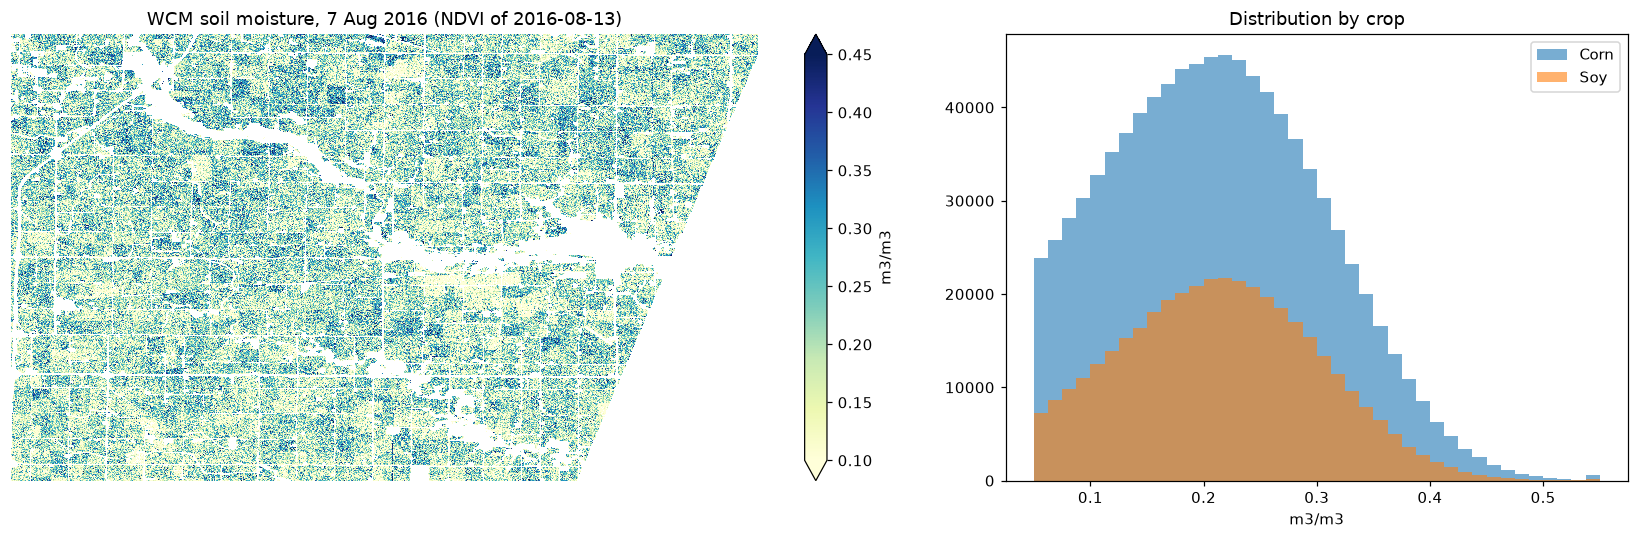

ThetaProbe 5 to 7 Aug: mean 0.243 (corn 0.237, soy 0.249); map: corn 0.179, soy 0.202 (medians)


In [7]:
scene = sd.smapvex16_scene("2016-08-07", 165)  # VV, VH, NDVI, CDL on 20 m
inc = float(df[df.orbit == 165].incidence.mean())  # incidence of this orbit over the domain
crop = xr.where(scene.cdl == 1, 1, xr.where(scene.cdl == 5, 2, np.nan))  # 1 corn, 2 soybean
theta = xr.full_like(scene.vv_db, np.nan)  # result
for code, name in ((1, "Corn"), (2, "Soy")):  # each crop
    sel = crop == code  # pixels
    th = sm.invert_wcm(scene.vv_db.where(sel), scene.ndvi.where(sel), inc, cal.loc[name].to_dict())  # inversion
    theta = theta.fillna(th.where(sel))  # fill
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]})  # map and histograms
theta.plot(ax=ax[0], cmap="YlGnBu", vmin=0.1, vmax=0.45, cbar_kwargs={"label": "m3/m3"}); ax[0].set_title(f"WCM soil moisture, 7 Aug 2016 (NDVI of {scene.attrs['s2_date']})"); ax[0].axis("off")  # map
for code, name in ((1, "Corn"), (2, "Soy")):  # histograms
    theta.where(crop == code).plot.hist(ax=ax[1], bins=40, alpha=0.6, label=name, range=(0.05, 0.55))  # distribution
ax[1].legend(); ax[1].set_xlabel("m3/m3"); ax[1].set_title("Distribution by crop"); plt.tight_layout(); plt.show()  # draw
obs = df[(df.date >= "2016-08-05") & (df.date <= "2016-08-07")]  # ThetaProbe days around the pass
print(f"ThetaProbe 5 to 7 Aug: mean {obs.sm.mean():.3f} (corn {obs[obs.crop == 'Corn'].sm.mean():.3f}, soy {obs[obs.crop == 'Soy'].sm.mean():.3f}); "
      f"map: corn {float(theta.where(crop == 1).median()):.3f}, soy {float(theta.where(crop == 2).median()):.3f} (medians)")  # check

The map shows soybean fields somewhat wetter than corn, as the ThetaProbe data did, but the medians
(0.18 under corn and 0.20 under soybean) are about 0.05 m3 m-3 lower than the field measurements of
5 to 7 August (0.24 and 0.25). Treat it as a pattern map; levels would need the per-field calibration
discussed above.

## Summary and exercises

- SMAPVEX16 gives 135 matched samples of field soil moisture, Sentinel-1 backscatter on three orbits,
  incidence angle and Sentinel-2 NDVI over 32 corn and soybean fields.
- The field soil moisture varied little (standard deviation 0.039 m3 m-3) and VV responded to it only
  in August; field-to-field roughness dominated in early June.
- An unconstrained Water Cloud Model overfits (0.20 m3 m-3 RMSE at new fields); bounding the soil
  sensitivity to physical values brings it to 0.085, still above the 0.039 of predicting the mean.
- The cross-polarization ratio is a usable vegetation descriptor without optical data.
- Bare-soil inversion of a single polarization with unknown roughness is ill-posed.
- Leave-one-field-out validation, and comparing against a no-skill baseline, are what reveal this; a
  calibration RMSE alone would have hidden it.

**Exercises**

1. Fit the WCM with `E` free (extend `bounds` and pass different `E` values) and compare the
   cross-validated RMSE.
2. Use VH instead of VV in the calibration. Is VH a better or worse soil moisture channel under the
   crops?
3. Add Dubois (`sm.dubois_model` with `sm.mironov_dielectric`) to the bare-soil comparison.
4. Map soil moisture for the 1 June 2016 pass (orbit 63) with `sd.smapvex16_scene("2016-06-01", 63)`.